In [31]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from typing import Any, Callable
import yfinance as yf

# Obtaining Prices for Analysis

In [32]:
# Stock and FX Data
start_date = '2010-01-01'
end_date = '2024-01-01'
stocks = ['AAPL', 'ASML.AS', 'AIR.PA', 'MC.PA', 'SC0D.DE', 'EURUSD=X']
stock_data = yf.download(' '.join(stocks), start=start_date, end=end_date)
# Combine data
data = pd.DataFrame(stock_data['Adj Close'].values, columns = stock_data['Adj Close'].columns, index = stock_data.index)

[*********************100%%**********************]  6 of 6 completed


In [34]:
# Interest Rate Data
euribor_3M = pd.read_csv("BundesBank Euribor 3M Daily.csv")
euribor_3M["Date"] = pd.to_datetime(euribor_3M["Date"], format='%Y-%m-%d')
euribor_3M = euribor_3M[(euribor_3M["Date"] >= pd.to_datetime(start_date)) & (euribor_3M["Date"] <= pd.to_datetime(end_date))]        # Keeping only the related dates
euribor_3M = euribor_3M.set_index('Date')
data = pd.merge(data, euribor_3M, on='Date', how='inner')

In [35]:
# Make names more readable
data = data.rename(columns={'ASML.AS': 'ASML', 'AIR.PA': 'AIRBUS', 'MC.PA': 'LVMH', 'SC0D.DE': 'EURO50', 'EURIBOR_3M': 'EURIBOR', 'EURUSD=X':'EUR_USD'})
# Delete Days for which no trading happened (some holiday probably, we didn't go to work)
data = data.loc[~(data[['AAPL', 'AIRBUS', 'ASML', 'LVMH', 'EURO50']].isnull()).all(axis=1)]
# Impute missing quotes with closest valid ones
data = data.ffill().bfill()
# Save for Model Validation
data.to_csv('stock_quotes_and_rates.csv')       # Saving

In [36]:
data

,AAPL,AIRBUS,ASML,EUR_USD,LVMH,EURO50,EURIBOR
Date,,,,,,,
2010-01-04,6.470740,11.523582,27.337233,1.442398,60.505985,47.728802,0.700
2010-01-05,6.481926,11.486514,27.387941,1.436596,60.221519,47.642601,0.699
2010-01-06,6.378824,11.589477,27.680918,1.440403,60.805817,47.599602,0.694
2010-01-07,6.367033,11.704796,27.173838,1.431803,61.497746,47.562500,0.692
2010-01-08,6.409362,11.820114,26.261099,1.441109,62.328083,47.728401,0.691
...,...,...,...,...,...,...,...
2023-12-22,193.353287,137.034973,682.389404,1.100619,737.700012,109.199997,3.931
2023-12-26,192.803986,137.034973,682.389404,1.102026,737.700012,109.199997,3.931
2023-12-27,192.903839,137.015320,683.687134,1.104301,735.400024,109.440002,3.925


### Calculating Credit Risk

In [37]:
def credit_risk(credit, short = True):
    """
    Function that calculates the loss at each time t of a loan
    """
    T = len(credit)
    t = np.arange(T)#.reshape((T, 1))

    # take the difference in yield
    x = credit.diff().fillna(0)

    # y is defines as the yield, i.e. the credit
    y = credit
    p = np.exp(-(T - t) * y)
    loss = p * (y - (T - t) * x) * ((-1) ** short)
    val = np.exp(np.cumsum(loss))
    # Slice the data to only have the dates in which the credit changed and fo a resample with a forward fill
    # .loc[slice].resample('1d').last().ffill()
    return loss, val

In [38]:
credit = ((1 + data['EURIBOR'] / 100) ** (1 / 365)) - 1
data['EURIBOR'] = credit
credit_loss, credit_val = credit_risk(data['EURIBOR'])

The `data` object now represents the risk factors $(Z_j)_{j\in I}$ of our portfolio, so that we can define $\ell_{[t]}^\Delta(Z)$.

In [39]:
data

,AAPL,AIRBUS,ASML,EUR_USD,LVMH,EURO50,EURIBOR
Date,,,,,,,
2010-01-04,6.470740,11.523582,27.337233,1.442398,60.505985,47.728802,0.000019
2010-01-05,6.481926,11.486514,27.387941,1.436596,60.221519,47.642601,0.000019
2010-01-06,6.378824,11.589477,27.680918,1.440403,60.805817,47.599602,0.000019
2010-01-07,6.367033,11.704796,27.173838,1.431803,61.497746,47.562500,0.000019
2010-01-08,6.409362,11.820114,26.261099,1.441109,62.328083,47.728401,0.000019
...,...,...,...,...,...,...,...
2023-12-22,193.353287,137.034973,682.389404,1.100619,737.700012,109.199997,0.000106
2023-12-26,192.803986,137.034973,682.389404,1.102026,737.700012,109.199997,0.000106
2023-12-27,192.903839,137.015320,683.687134,1.104301,735.400024,109.440002,0.000105


In [40]:
# Weights, if we use as Daan derived (Converting $ currencies to EUR)
weights = [.2, .1, .1, .0, .1 , .1, .4]     # AAPL$, AIRBUS€, ASML€, EUR_USD, LVMH€, EURO50€, EURIBOR
data['AAPL'] = data['AAPL'] / data['EUR_USD']

<Axes: xlabel='Date'>

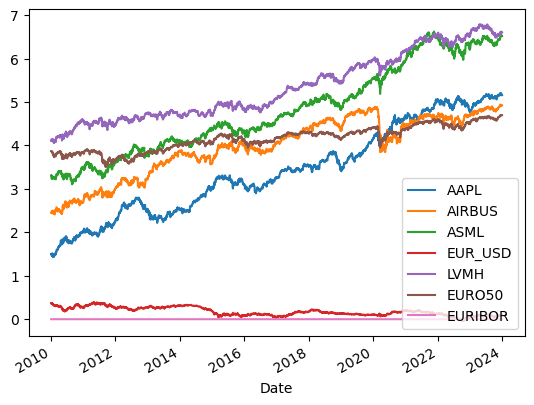

In [41]:
log_data = data
log_data[data.columns[:-1]] = np.log(data[data.columns[:-1]])

log_data.plot()

# Declaring Loss Operator

In [42]:
def loss_operator(Z, weights, Value: float = 10 ** 8):
    """
    The loss distribution is the weighted sum of negative log returns (X) multiplied by exp(Z(t) - Z(0)) where Z(x) is the log price at time x

    NOTE: For us, Z(0) = 0 as I standardised all returns at t = 0
    """
    loss = np.zeros(len(Z) - 1)
    loss_ind = Z[:-1].copy()
    T = len(Z) - 1
    t = np.arange(T)
    for Z_k, weight, name in zip(Z.values.T, weights, Z.columns):
        X_k = np.diff(Z_k)
        X_k = np.array([0] + X_k.tolist())
        X_k_shifted = X_k[1:] # from t = 2 to T
        X_k = X_k[:-1]  # from t = 1 to T - 1
        Z_k = Z_k[:-1]
        if name == 'AAPL':
            # Include EUR/USD exposure
            loss_sub = Value * weight * np.exp((Z_k - Z_k[0]) + (Z['EUR_USD'][:-1] - Z['EUR_USD'][0])) * X_k_shifted
        elif name == 'EURIBOR':
            # The time risk
            w = Value * np.exp(Z_k[0])
            loss_sub = -w * np.exp(-(T-t) * Z_k) * Z_k

            # Add credit risk
            loss_sub += Value * weight * np.exp(Z_k[0] - (T - t) * Z_k) * (T - t) * X_k
        else:
            loss_sub = Value * weight * np.exp(Z_k - Z_k[0]) * X_k_shifted
        loss += loss_sub
        loss_ind[name] = loss_sub * (1 / (weight)) if name != 'EUR_USD' else 0
    return loss, loss_ind

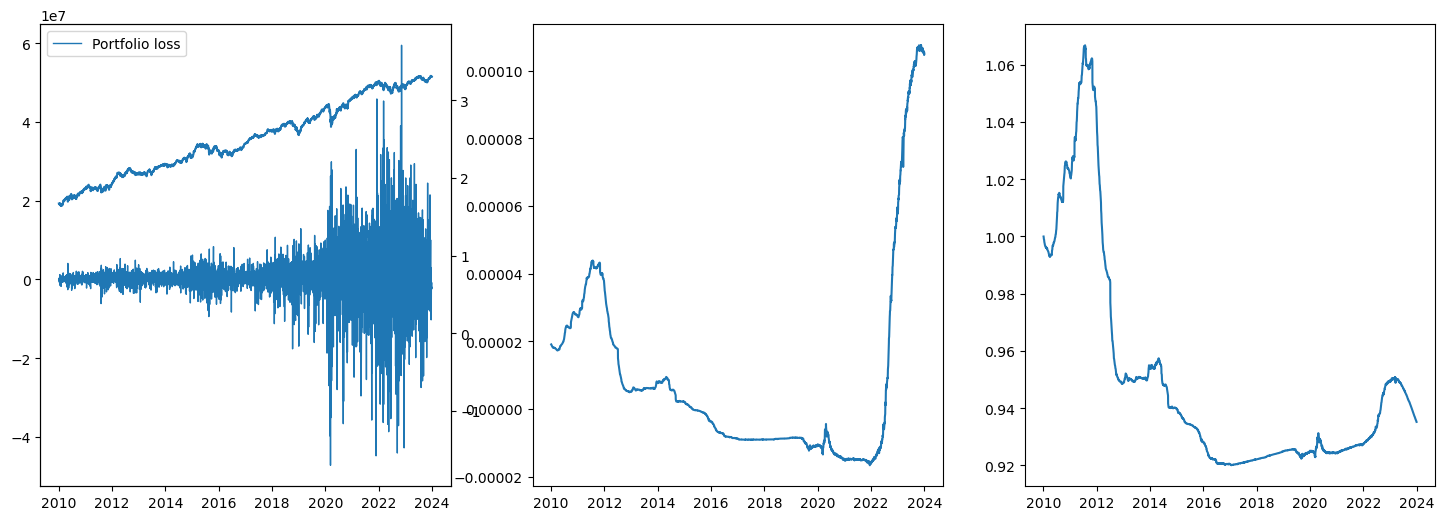

In [43]:
portfolio_loss, ind_loss = loss_operator(data, weights)
fig, axs = plt.subplots(1,3, figsize = (18, 6))
axs[0].plot(portfolio_loss, label = 'Portfolio loss', lw = 1)
ax = axs[0].twinx()
PV = np.sum(weights * data, axis = 1)
ax.plot(PV)
ax.set_ylim(1.2 * max(-PV), 1.2 * max(PV))
axs[1].plot(data['EURIBOR'])
axs[2].plot(credit_val.loc[data.index])
axs[0].legend()
plt.show()

# Declaring methods to calculate VaR

### VaR CoVar

In [44]:
def Var_Cov_VaR(data: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """

    pf_vol = [np.nan] * window_size
    for k in range(window_size, len(data)):
        COV = data[k - window_size: k].cov(ddof = 0)
        pf_vol.append(
            np.sqrt(port_weights @ COV @ port_weights)
        )

    pf_vol = np.array(pf_vol)
    # rolling_vol: pd.DataFrame = data.shift(-1).rolling(window = window_size).var(ddof = 0).shift(1).dropna()
    # portfolio_volatility: np.array | Any = rolling_vol.values @ port_weights
 
    portfolio_VaR = pd.DataFrame(pf_vol, index = data.index, columns = ['Vol'])
    portfolio_VaR['VaR'] = pf_vol * dist(alpha, **kwargs)
    return portfolio_VaR.dropna()

def Var_Cov_ES(Vol: Any, alpha: float, dist: Callable, **kwargs) -> float:
    """
    Calculate the expected shortfall
    """
    alpha = 1 - alpha
    match dist:
        case stats.norm:
            q: float = stats.norm.isf(alpha)
            p: float = stats.norm.pdf(q)
            return Vol * p / (alpha)
        case stats.t:
            df: int | float = kwargs.get('df', 4)
            q: float = stats.t.isf(alpha, df = df)
            p: float = stats.t.pdf(q, df = df)
            return Vol * ((df + (q ** 2)) / (df - 1)) * p / (alpha)
        case _:
            raise NotImplementedError() 

In [45]:
window_size = 250 # days
VaR_HS_normal_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.norm.ppf)
VaR_HS_student4_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 4)
VaR_HS_student5_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 5)
VaR_HS_student6_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 6)

ES_HS_normal_1 = Var_Cov_ES(VaR_HS_normal_1.Vol, alpha = .95, dist = stats.norm)
ES_HS_student4_1 = Var_Cov_ES(VaR_HS_student4_1.Vol, alpha = .95, dist = stats.t, df = 4)
ES_HS_student5_1 = Var_Cov_ES(VaR_HS_student5_1.Vol, alpha = .95, dist = stats.t, df = 5)
ES_HS_student6_1 = Var_Cov_ES(VaR_HS_student6_1.Vol, alpha = .95, dist = stats.t, df = 6)

loss_df_sliced = portfolio_loss[window_size:]

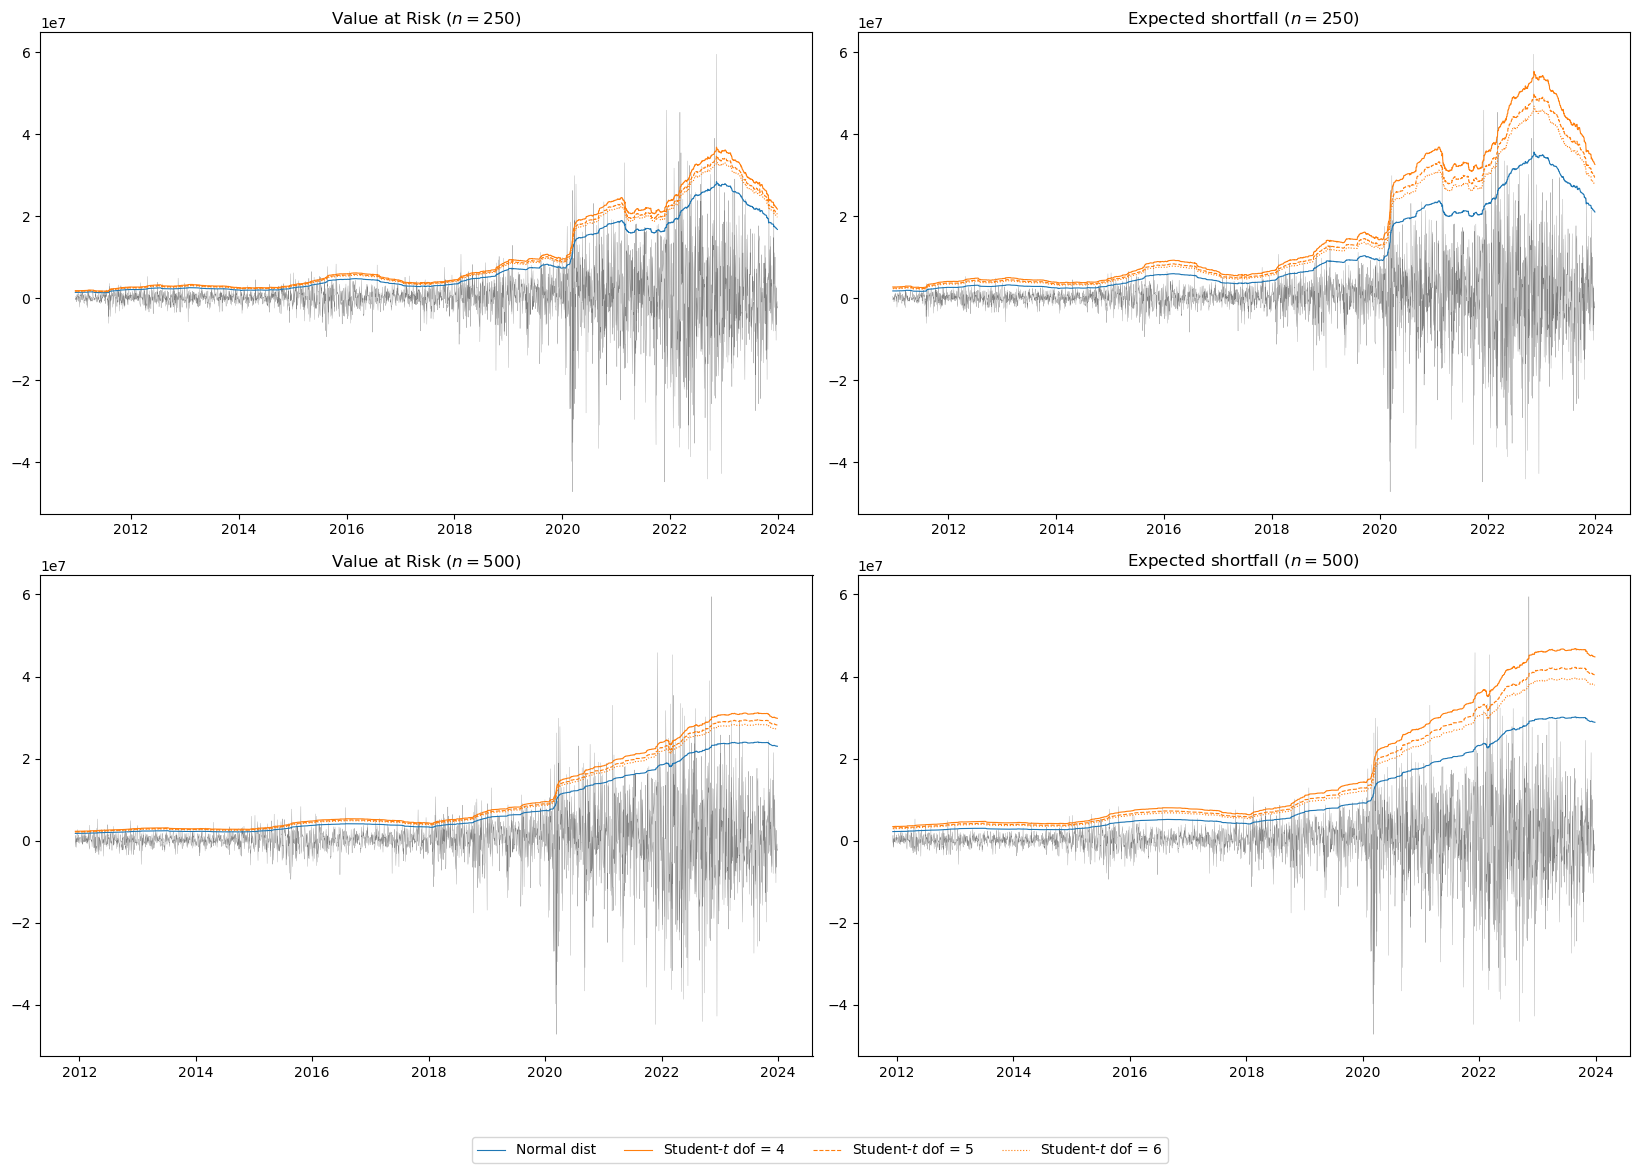

In [46]:
fig, axs = plt.subplots(2, 2, figsize = (16.5, 16.5 / 1.5)) #(8.2543, 8.2543 / 3)
axs[0,1].set_title('Expected shortfall $(n = 250)$')
axs[0,1].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[0,1].plot(ES_HS_normal_1, label = 'Normal dist', lw = .8)
axs[0,1].plot(ES_HS_student4_1, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[0,1].plot(ES_HS_student5_1, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[0,1].plot(ES_HS_student6_1, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[0,0].set_title('Value at Risk $(n = 250)$')
axs[0,0].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[0,0].plot(VaR_HS_normal_1.VaR, label = 'Normal dist', lw = .8)
axs[0,0].plot(VaR_HS_student4_1.VaR, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[0,0].plot(VaR_HS_student5_1.VaR, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[0,0].plot(VaR_HS_student6_1.VaR, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)

window_size = 500 # days
VaR_HS_normal_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.norm.ppf)
VaR_HS_student4_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 4)
VaR_HS_student5_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 5)
VaR_HS_student6_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 6)

ES_HS_normal_1 = Var_Cov_ES(VaR_HS_normal_1.Vol, alpha = .95, dist = stats.norm)
ES_HS_student4_1 = Var_Cov_ES(VaR_HS_student4_1.Vol, alpha = .95, dist = stats.t, df = 4)
ES_HS_student5_1 = Var_Cov_ES(VaR_HS_student5_1.Vol, alpha = .95, dist = stats.t, df = 5)
ES_HS_student6_1 = Var_Cov_ES(VaR_HS_student6_1.Vol, alpha = .95, dist = stats.t, df = 6)

loss_df_sliced = portfolio_loss[window_size:]

axs[1,1].set_title('Expected shortfall $(n = 500)$')
axs[1,1].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[1,1].plot(ES_HS_normal_1, label = 'Normal dist', lw = .8)
axs[1,1].plot(ES_HS_student4_1, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[1,1].plot(ES_HS_student5_1, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[1,1].plot(ES_HS_student6_1, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[1,0].set_title('Value at Risk $(n = 500)$')
axs[1,0].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[1,0].plot(VaR_HS_normal_1.VaR, label = 'Normal dist', lw = .8)
axs[1,0].plot(VaR_HS_student4_1.VaR, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[1,0].plot(VaR_HS_student5_1.VaR, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[1,0].plot(VaR_HS_student6_1.VaR, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[0].legend(bbox_to_anchor=(0.5, -.3), loc='center', ncol=5)
lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes][:1]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)][:2]
fig.legend(lines, labels, bbox_to_anchor=(0.5, -.05), loc='center', ncol=4)
fig.tight_layout()
plt.savefig('HS.pdf')
plt.show()

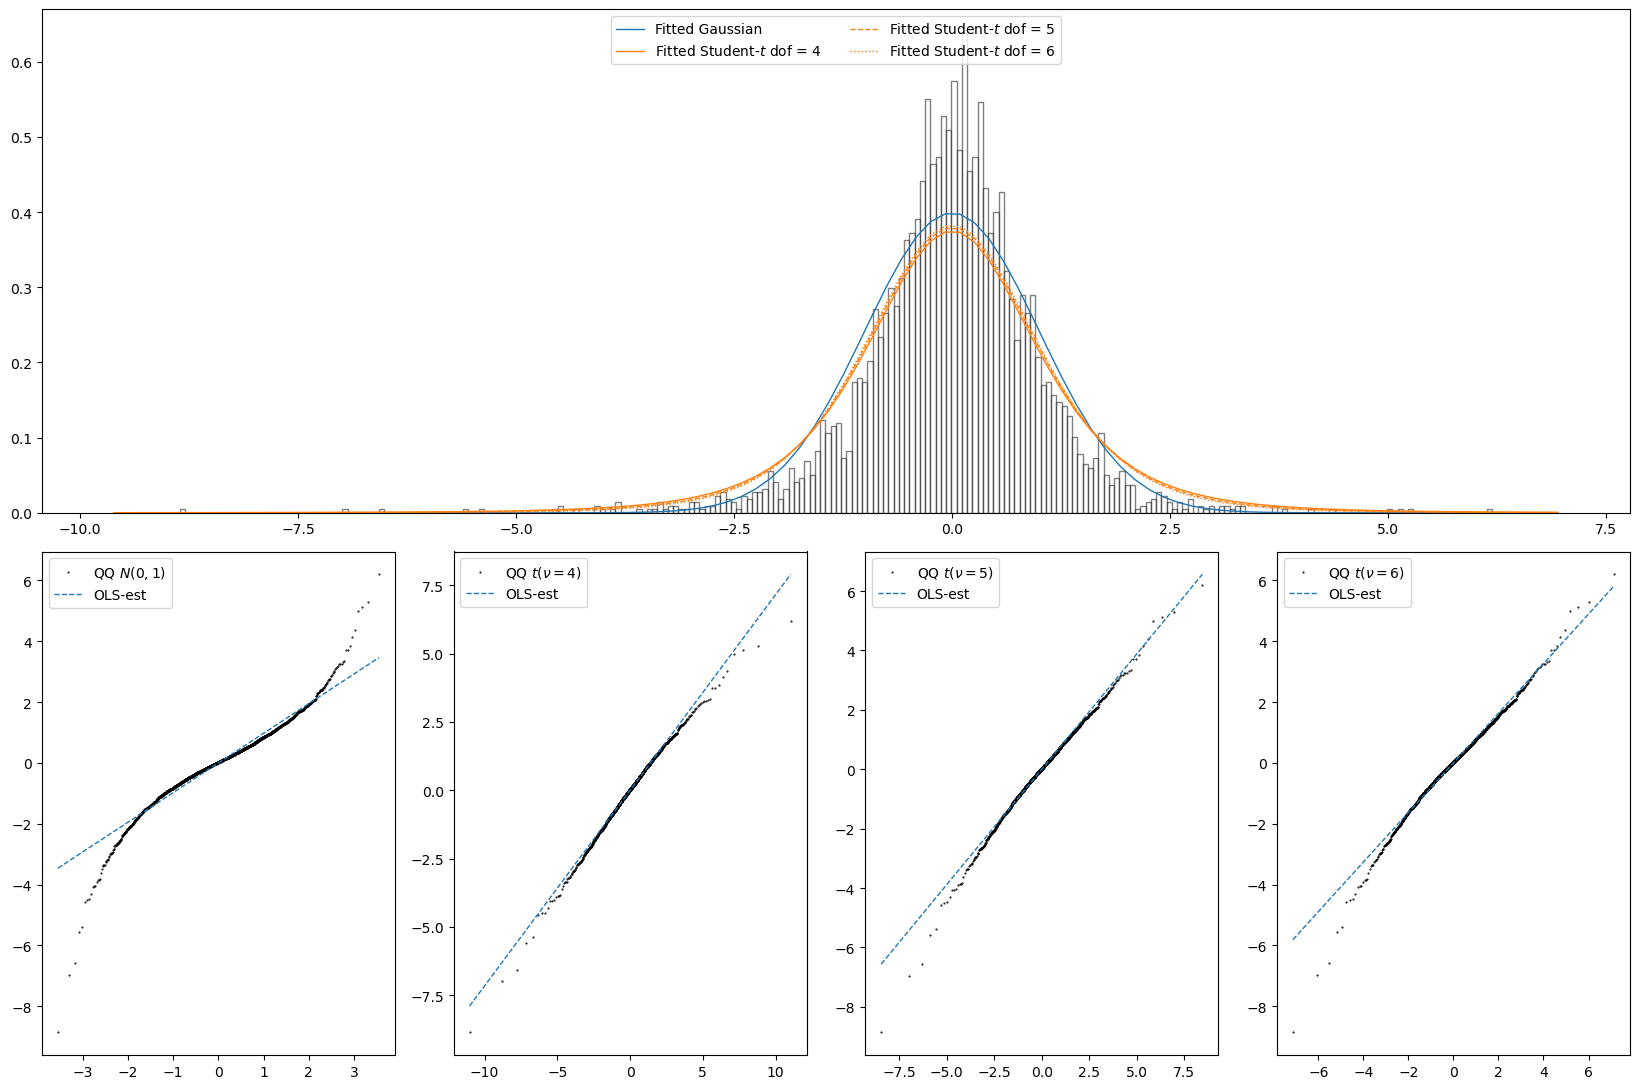

In [47]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import matplotlib as mpl

# Generate some random data
data = (log_data.diff() @ weights).dropna()
data = (data - data.mean()) / data.std()

# Create figure and subplots
# fig, axs = plt.subplots(2, 4, figsize=(12, 5))

# Plot histogram with density curve
fig = plt.figure(figsize = (16.5, 16.5 / 1.5))
gs = mpl.gridspec.GridSpec(2, 4)#, wspace=0.25, hspace=0.25) # 2x2 grid
axs = fig.add_subplot(gs[0, :]) # first row, first col
axs1 = fig.add_subplot(gs[1, 1]) # first row, second col
axs2 = fig.add_subplot(gs[1, 2])
axs3 = fig.add_subplot(gs[1, 3])
axs4 = fig.add_subplot(gs[1, 0])


axs.hist(data, bins=250, density=True, alpha=0.5, color='white', edgecolor='black')
xmin, xmax = axs.get_xlim()
x = np.linspace(xmin, xmax, 100)
pdf = stats.norm.pdf(x)
axs.plot(x, pdf, linewidth=1, ls = '-', label = 'Fitted Gaussian')
pdf = stats.t.pdf(x, loc = np.mean(data), scale = np.std(data), df = 4)
axs.plot(x, pdf, linewidth=1, ls = '-', label = 'Fitted Student-$t$ dof = 4', c = 'C1')
stats.probplot(data, dist=stats.t, plot=axs1, sparams = (4,))
axs1.get_lines()[1].set_color('C0')
axs1.get_lines()[1].set_linestyle('dashed')
axs1.get_lines()[1].set_linewidth(1)
axs1.get_lines()[0].set_marker('.')  # Set marker style to dots
axs1.get_lines()[0].set_color('black')  # Set marker color to black
axs1.get_lines()[0].set_markersize(1)  # Set marker size
# axs1.set_title('QQ Plot')

pdf = stats.t.pdf(x, df = 5)
axs.plot(x, pdf, linewidth=1, ls = 'dashed', label = 'Fitted Student-$t$ dof = 5', c = 'C1')
stats.probplot(data, dist=stats.t, plot=axs2, sparams = (5,))
axs2.get_lines()[1].set_color('C0')
axs2.get_lines()[1].set_linestyle('dashed')
axs2.get_lines()[1].set_linewidth(1)
axs2.get_lines()[0].set_marker('.')  # Set marker style to dots
axs2.get_lines()[0].set_color('black')  # Set marker color to black
axs2.get_lines()[0].set_markersize(1)  # Set marker size
# axs2.set_title('QQ Plot')

pdf = stats.t.pdf(x, df = 6)
axs.plot(x, pdf, linewidth=1, ls = 'dotted', label = 'Fitted Student-$t$ dof = 6', c = 'C1')
stats.probplot(data, dist=stats.t, plot=axs3, sparams = (6,))
axs3.get_lines()[1].set_color('C0')
axs3.get_lines()[1].set_linestyle('dashed')
axs3.get_lines()[1].set_linewidth(1)
axs3.get_lines()[0].set_marker('.')  # Set marker style to dots
axs3.get_lines()[0].set_color('black')  # Set marker color to black
axs3.get_lines()[0].set_markersize(1)  # Set marker size
# axs3.set_title('QQ Plot')

axs.legend(loc = 'upper center', ncol = 2)

# axs3.set_title('Histogram with Density')
# Plot QQ plot
stats.probplot(data, dist="norm", plot=axs4)
axs4.get_lines()[1].set_color('C0')
axs4.get_lines()[1].set_linestyle('dashed')
axs4.get_lines()[1].set_linewidth(1)
axs4.get_lines()[0].set_marker('.')  # Set marker style to dots
axs4.get_lines()[0].set_color('black')  # Set marker color to black
axs4.get_lines()[0].set_markersize(1)  # Set marker size
# axs4.set_title('QQ Plot')

axs1.set_xlabel(None)
axs2.set_xlabel(None)
axs3.set_xlabel(None)
axs4.set_xlabel(None)

axs1.set_ylabel(None)
axs2.set_ylabel(None)
axs3.set_ylabel(None)
axs4.set_ylabel(None)

axs1.set_title(None)
axs2.set_title(None)
axs3.set_title(None)
axs4.set_title(None)
# Adjust layout
# plt.tight_layout()
axs1.legend([r'QQ $t(\nu = 4)$','OLS-est'])
axs2.legend([r'QQ $t(\nu = 5)$','OLS-est'])
axs3.legend([r'QQ $t(\nu = 6)$','OLS-est'])
axs4.legend([r'QQ $N(0,1)$','OLS-est'])
# Show plot
plt.tight_layout()
plt.savefig('QQ.pdf')
plt.show()


### Other Methods

In [48]:
def volatility(omega, alpha, beta, x):
    # this function is the main volatility filter needed to obtain the results while estimating

    T =len(x)

    # Filter Volatility
    sig     = np.zeros(T)
    sig[0]  = np.var(x[:50], ddof = 0); #initialize volatility at unconditional variance

    # loop iteratively over the indices and define the volatilities in that way
    for t in range(0,T-1):
        if t % 365 == 0:
            if t != 0:
                omega = np.var(x[t - 365: t]) * (1 - alpha - beta)
        sig[t+1] = omega + alpha *  (x[t]**2) + beta * sig[t]

    return sig ** .5

def GARCH_portfolio_variance(data: pd.DataFrame, weights: np.array):
    CM: np.matrix | pd.DataFrame = data.corr().fillna(0)
    n: int = CM.shape[0]
    weights = np.array(weights)
    W = weights.reshape((n, 1)) * weights.reshape((1,len(weights)))
    CMU: np.matrix = CM * W
    
    vol_df = data * 0
    for asset in data.columns:
        x = data[asset]
        alpha, beta = .05, .93
        omega = np.var(x[:365]) * (1 - alpha - beta)
        vol_df[asset] = volatility(omega, alpha, beta, x)
      
    vol = []
    
    Sigm = vol_df.values
    for row in Sigm:
        # Variance as outer product of the weights with the covariance
        vol.append(row @ CMU @ row)
    return np.array(vol) ** .5

def GARCH_VaR(vol, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """
    return vol * dist(alpha, **kwargs)


def devol(data: pd.DataFrame, pf_loss, window_size: int, port_weights: np.array, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """

    pf_vol = [np.nan] * window_size
    for k in range(window_size, len(data)):
        COV = data[k - window_size: k].cov(ddof = 0)
        pf_vol.append(
            np.sqrt(port_weights @ COV @ port_weights)
        )

    pf_vol = np.array(pf_vol)
    
    # rolling_vol: pd.DataFrame = data.shift(-1).rolling(window = window_size).var(ddof = 0).shift(1).dropna()
    # portfolio_volatility: np.array | Any = rolling_vol.values @ port_weights
 
    portfolio_VaR = pd.DataFrame(pf_vol, index = data.index, columns = ['Vol'])
    return pf_loss / portfolio_VaR.Vol

In [49]:
def Historic_Simulation(portfolio_risk: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, **kwargs) -> float:
    """
    Calculate VaR and ES using historic simulation
    """

    # Calculate the volatility
    df = pd.DataFrame([], index = portfolio_risk.index, columns = ['VaR'])
    VaR = portfolio_risk.rolling(window = window_size).quantile(alpha)
    ES  = [np.nan] * window_size
    for k in range(window_size, len(portfolio_risk)):
        _ = portfolio_risk.iloc[k - window_size: k]
        _ = _[_ >= VaR.iloc[k]]
        ES.append(np.mean(_))
        
    df['VaR'] = VaR
    df['ES'] = ES
    return df.dropna()

def filtered_HS(portfolio_risk_ind, weights, _alpha, window_size):
    Devol = pd.DataFrame([], index = portfolio_risk_ind.index)
    Vol = pd.DataFrame([], index = portfolio_risk_ind.index)
    for col in portfolio_risk_ind.columns:
        # Filter the volatility for each individual asset using the EWMA method
        x = portfolio_risk_ind[col]
        alpha = .05
        beta = 1 - alpha
        omega = 0
        vol = volatility(omega, alpha, beta, x)
        Vol[f'Vol {col}'] = vol
        Devol[f'Devol {col}'] = portfolio_risk_ind[col] / vol 
    # Calculate the portfolio volatility (not sure if correct)
    Devol = Devol.fillna(0)
    df = pd.DataFrame([], index = portfolio_risk_ind.index, columns = ['VaR'])

    # Define a rolling window VaR estimator
    ES  = [np.nan] * window_size
    VaR = [np.nan] * window_size
    for k in range(window_size, len(portfolio_risk_ind)):
        # Get the window over the devol object, and multiply with the predicted volatility
        D = Devol.iloc[k - window_size: k] * Vol.iloc[k].values

        # get the returns and calculate the VaR
        portfolio_returns = D @ weights
        VaR.append(portfolio_returns.rolling(window = window_size).quantile(_alpha).iloc[-1])
        
        _ = portfolio_returns[portfolio_returns >= VaR[k]]
        # The expected shortfall is the mean of the returns conditional on exceeding the var
        ES.append(np.mean(_))
    df['VaR'] = VaR
    df['ES'] = np.array(ES)
    return df#.dropna()

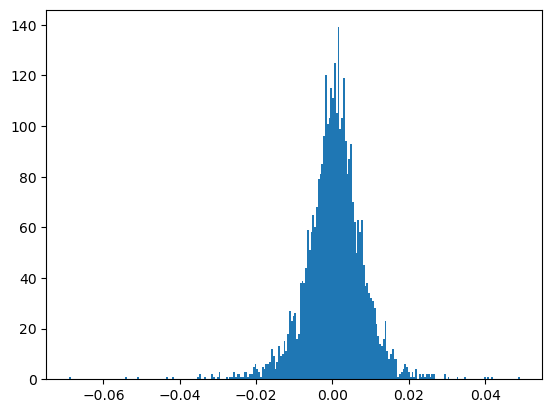

In [50]:
plt.hist(log_data.diff() @ weights, bins = 250)
plt.show()

In [51]:
VaR_ES_Historic_Simulation = Historic_Simulation(portfolio_loss, window_size, weights, .95)

In [52]:
EWMA_HS = filtered_HS(ind_loss, weights, .95, window_size)
GARCH = GARCH_portfolio_variance(ind_loss, weights = weights)
VaR_GARCH = GARCH_VaR(GARCH, .95, stats.norm.ppf)
ES_GARCH = Var_Cov_ES(GARCH, .95, stats.norm)
ES_GARCH = pd.DataFrame(ES_GARCH, index = ind_loss.index)


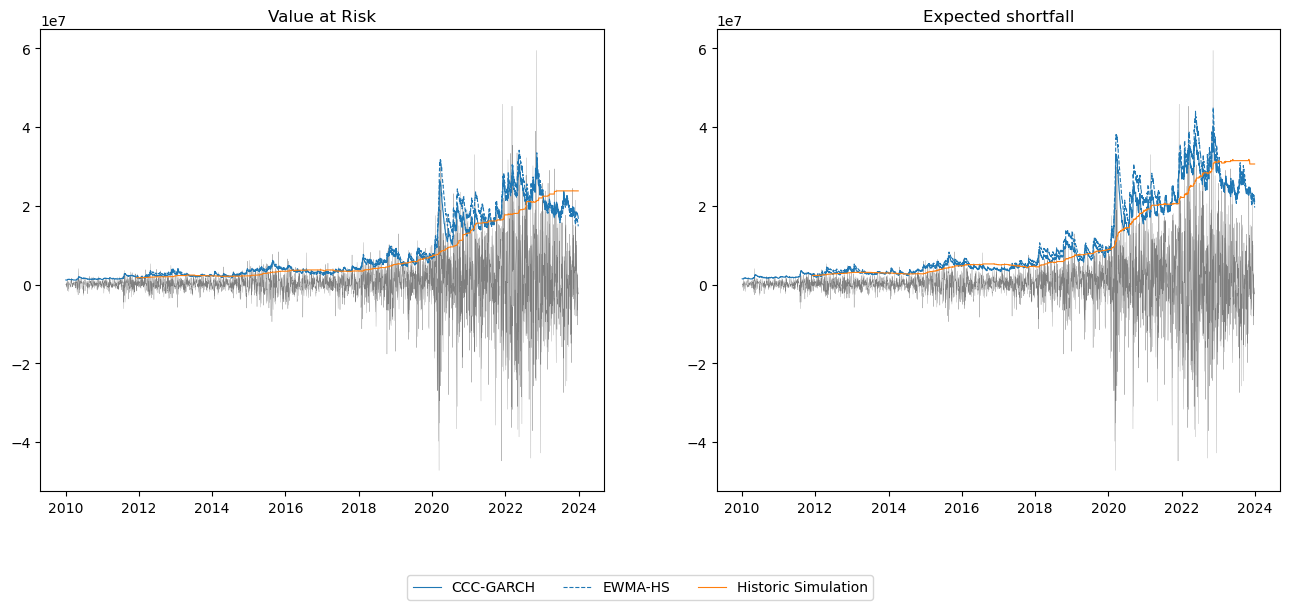

In [53]:
fig, axs = plt.subplots(1, 2, figsize = (16, 6))
# fig, axs = plt.subplots(1, 2, figsize = (8.2543, 8.2543 / 3))
axs[1].set_title('Expected shortfall')
axs[1].plot(portfolio_loss, lw = .2, c = 'black', alpha = .5)
axs[1].plot(portfolio_loss.index, ES_GARCH, label = 'CCC-GARCH', lw = .8, c = 'C0')
axs[1].plot(EWMA_HS.ES, label = 'EWMA-HS', lw = .8, c = 'C0', ls = 'dashed')
axs[1].plot(VaR_ES_Historic_Simulation.ES, label = 'Historic Simulation', lw = .8, c = 'C1')
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[0].set_title('Value at Risk')
axs[0].plot(portfolio_loss, lw = .2, c = 'black', alpha = .5)
axs[0].plot(portfolio_loss.index, VaR_GARCH, label = 'CCC-GARCH', c = 'C0', lw = .8)
axs[0].plot(EWMA_HS.VaR, label = 'EWMA-HS', lw = .8, c = 'C0', ls = 'dashed')
axs[0].plot(VaR_ES_Historic_Simulation.VaR, label = 'Historic Simulation', lw = .8, c = 'C1')
# axs[0].legend(bbox_to_anchor=(0.5, -.3), loc='center', ncol=5)
lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes][:1]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)][:2]
fig.legend(lines, labels, bbox_to_anchor=(0.5, -.05), loc='center', ncol=4)
plt.show()

# Old Unused stuff under here? (Looks like from old file, and does not compile, so I assume just drop it, plug-in from old file whatever I have kept for backtest)

In [54]:
def VaR_violations(loss: pd.DataFrame, VaR: object) -> ...:
    try: 
        vv = np.where(loss >= VaR, 1, 0)
        vv = pd.DataFrame(vv, index = loss.index, columns = ['violation dates'])
    except: 
        vv = np.where(loss.loc[VaR.index] >= VaR, 1, 0)
        vv = pd.DataFrame(vv, index = VaR.index, columns = ['violation dates'])
    return vv[vv['violation dates'] == 1].index, vv

In [55]:
VaR_violations_normal_dates, VaR_violations_normal = VaR_violations(loss_df_sliced, VaR_HS_normal.VaR)
VaR_violations_t4_dates, VaR_violations_t4 = VaR_violations(loss_df_sliced, VaR_HS_student4.VaR)
VaR_violations_t5_dates, VaR_violations_t5 = VaR_violations(loss_df_sliced, VaR_HS_student5.VaR)
VaR_violations_t6_dates, VaR_violations_t6 = VaR_violations(loss_df_sliced, VaR_HS_student6.VaR)
VaR_violations_garch_dates, VaR_violations_garch = VaR_violations(portfolio_loss, VaR_GARCH)
VaR_violations_ewma_dates, VaR_violations_ewma = VaR_violations(portfolio_loss, VaR_ES_Historic_Simulation.VaR)

VaRS = [
    VaR_violations_normal_dates,
    VaR_violations_t4_dates, 
    VaR_violations_t5_dates,
    VaR_violations_t6_dates,
    VaR_violations_garch_dates,
    VaR_violations_ewma_dates,
]

years = pd.to_datetime([str(2010 + i) for i in range(10)])
years = list(zip(years[:-1], years[1:]))

NameError: name 'VaR_HS_normal' is not defined

In [ ]:
fig, axs = plt.subplots(len(VaRS), 1, figsize = (18, 18))
for i, y in enumerate(VaRS):
    for x in y: axs[i].axvline(x, c = 'red', lw = .2)
    sliced = portfolio_loss.loc[loss_df_sliced.index]
    m = max(sliced.abs())
    axs[i].axhline(0, c = 'black', ls = '--', lw = .5)
    axs[i].plot(sliced, lw = .3, alpha = 1) 
    axs[i].set_ylim([-1.2 * m, 1.2 * m])
plt.show()

NameError: name 'VaRS' is not defined

In [ ]:
def get_actual_ES(risk, years, ES_pred, alpha = .95):
    for start, end in years:
        sliced = risk[(risk.index < end) & (risk.index >= start)]
        VaR = sliced.quantile(alpha)
        ES = np.mean(sliced[sliced >= VaR])
        ES_act = str(np.round(ES, 4)).ljust(6, '0')
        _ = np.mean(ES_pred[(ES_pred.index < end) & (ES_pred.index > start)])
        ES_pred_sliced = str(np.round(_, 4)).ljust(6, '0')
        dis = str(np.round(100 * _ / ES, 2)).ljust(2, '0')
        print(f'Actual vs predicted ES between {start.date()} and {end.date()}: {ES_act} vs {ES_pred_sliced} ({dis}%)')

names = [
    (ES_HS_normal, 'normal'), (ES_HS_student4, 'student t 4'), (ES_HS_student5, 'student t 5'), (ES_HS_student6, 'student t 6'), (ES_GARCH, 'garch'), (EWMA_HS, 'ewma')
]

NameError: name 'ES_HS_normal' is not defined

In [ ]:
for m, n in names:
    print(n)
    get_actual_ES(portfolio_loss, years, m)
    print('')

NameError: name 'names' is not defined

In [ ]:
# # Reading Log Returns for Each Asset and the Interest Rates for the Credit

# # STOCK DATA
# portfolio_df = pd.read_csv("_portfolio_returns.csv", index_col=["Date"], parse_dates = True).drop(columns=["EUR_USD"])
# loss_df = -portfolio_df
# # loss_df = loss_df.drop(columns=["EUR_USD"]) # For now just drop, need answer to Q1
# # loss_df = loss_df*(-1)      # Converting into Loss Distribution. instead of P/L, IT IS THAT SIMPLE RIGHT?

# # Reading Rates for Credit
# euribor = pd.read_csv("_EURIBOR_monthly_rates.csv", index_col=["Date"], parse_dates=True)
# eb_index = euribor.index
# euribor = euribor.resample('1d').last().ffill()
# # ...       # Nothing for now, need answer to Q2
# loan_position = (1 - (euribor / 100)) ** (1 / 365) - 1

# loss_df = loss_df.loc[loan_position.index]
# portfolio_df = portfolio_df.loc[loan_position.index]
# # Declaring weights for portfolio construction, DON'T FORGET TO UPDAtE ONCE CREDIT IS ADDED
# PORTFOLIO_WEIGHTS= np.array([0.15, 0.30, 0.05, 0.15, 0.15, 0.2])    # If we short something we can get more cash to invest
# PORTFOLIO_WEIGHTS = np.array((PORTFOLIO_WEIGHTS / (4 / 3)).tolist() + [.25]) # 25% in a shorted bond

In [ ]:
log_returns = portfolio_df

NameError: name 'portfolio_df' is not defined

In [ ]:
N = len(portfolio_df.columns)
starting_returns = pd.DataFrame(np.zeros((1,N)), index = [pd.to_datetime('2015-01-30')], columns = portfolio_df.columns)

In [ ]:
log_returns = pd.concat([starting_returns, log_returns])
Z = np.log(np.exp(log_returns).cumprod())

In [ ]:
def credit_risk(credit, short = True):
    """
    Function that calculates the loss at each time t of a loan
    """
    # We define the end time
    credit = 1 + credit / 100

    # Translate annual yield to daily yield
    credit = credit ** (1 / 365) - 1
    T = len(credit)
    t = np.arange(T).reshape((T, 1))

    # take the difference in yield
    x = credit.diff().fillna(0)

    # y is defines as the yield, i.e. the credit
    y = credit
    p = np.exp(-(T - t) * y)
    loss = p * (y - (T - t) * x) * ((-1) ** short)
    val = np.exp(np.cumsum(loss))
    # Slice the data to only have the dates in which the credit changed and fo a resample with a forward fill
    # .loc[slice].resample('1d').last().ffill()
    return loss, val

In [ ]:
euribor = pd.concat([pd.DataFrame(0.0627, index = [pd.to_datetime('2015-01-30')], columns = ['EURIBOR_3M']), euribor])

In [ ]:
credit = euribor
loss, val = credit_risk(credit)

In [ ]:
Z['loan'] = np.log(val)
log_returns['loan'] = -loss

In [ ]:
def loss_operator(Z, X, weights, Value: float = 10 ** 8):
    """
    The loss distribution is the weighted sum of negative log returns (X) multiplied by exp(Z(t) - Z(0)) where Z(x) is the log price at time x

    NOTE: For us, Z(0) = 0 as I standardised all returns at t = 0
    """
    loss = Value * np.sum(weights * np.exp(Z) * X, axis = 1)
    loss_ind = Value * np.exp(Z) * X
    return loss_ind, loss

In [ ]:
loss_df, loss_df_portfolio = loss_operator(Z = Z, X = log_returns, weights = PORTFOLIO_WEIGHTS)

In [ ]:
credit = euribor
loss, val = credit_risk(credit)
plt.axhline(1, lw = 1, c = 'black', ls = '--')
plt.plot(1 + loss, label = 'credit risk')
plt.plot(val, label = 'value short bond')
plt.plot(1 + credit / 100, label = 'yield')
plt.legend()
plt.show()

In [ ]:
fig, axs = plt.subplots(1,3, figsize = (18, 6))
axs[0].plot(PORTFOLIO_WEIGHTS * loss_df, label = loss_df.columns, lw = 1)
axs[1].plot(euribor)
axs[2].plot(loss_df.loan)
axs[0].legend()
plt.show()

In [ ]:
from typing import Callable, Any

def PortRet(*, data: pd.DataFrame, weights: np.array) -> pd.DataFrame:

    assert np.sum(weights) == 1
    return data @ weights

Include $V\lambda\exp(Z(t)-Z(0))=V\lambda\exp(\log S(t)/S(0))=V\lambda S(t)/S(0)$

In [ ]:
def loss_operator(log_returns: pd.DataFrame, yield_curve: pd.DataFrame, weights: Any, value: float = 1.0):
    """
    The first order tayler expansion of the loss operator L
    """

    daily_yield_curve = (1 + yield_curve / 100) ** (1 / 365) - 1
    T = len(log_returns)
    t = np.arange(T).reshape((T,1))
    X_yield = daily_yield_curve.diff()
    derivative_time = -np.exp(-(T - t) * daily_yield_curve) * daily_yield_curve


In [ ]:
def Var_Cov_VaR(data: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """

    pf_vol = [np.nan] * window_size
    for k in range(window_size, len(data)):
        COV = data[k - window_size: k].cov(ddof = 0)
        pf_vol.append(
            np.sqrt(port_weights @ COV @ port_weights)
        )

    pf_vol = np.array(pf_vol)
    # rolling_vol: pd.DataFrame = data.shift(-1).rolling(window = window_size).var(ddof = 0).shift(1).dropna()
    # portfolio_volatility: np.array | Any = rolling_vol.values @ port_weights
 
    portfolio_VaR = pd.DataFrame(pf_vol, index = data.index, columns = ['Vol'])
    portfolio_VaR['VaR'] = pf_vol * dist(alpha, **kwargs)
    return portfolio_VaR.dropna()

def Var_Cov_ES(Vol: Any, alpha: float, dist: Callable, **kwargs) -> float:
    """
    Calculate the expected shortfall
    """
    alpha = 1 - alpha
    match dist:
        case stats.norm:
            q: float = stats.norm.isf(alpha)
            p: float = stats.norm.pdf(q)
            return Vol * p / (alpha)
        case stats.t:
            df: int | float = kwargs.get('df', 4)
            q: float = stats.t.isf(alpha, df = df)
            p: float = stats.t.pdf(q, df = df)
            return Vol * ((df + (q ** 2)) / (df - 1)) * p / (alpha)
        case _:
            raise NotImplementedError() 

In [ ]:
def volatility(omega, alpha, beta, x):
    # this function is the main volatility filter needed to obtain the results while estimating

    T =len(x)

    # Filter Volatility
    sig     = np.zeros(T)
    sig[0]  = np.var(x[:50], ddof = 0); #initialize volatility at unconditional variance

    # loop iteratively over the indices and define the volatilities in that way
    for t in range(0,T-1):
        sig[t+1] = omega + alpha *  (x[t]**2) + beta * sig[t]

    return sig ** .5

def GARCH_portfolio_variance(data: pd.DataFrame, weights: np.array):
    CM: np.matrix | pd.DataFrame = data.corr()
    n: int = CM.shape[0]
    W = weights.reshape((n, 1)) * weights.reshape((1,len(weights)))
    CMU: np.matrix = CM * W
    
    vol_df = data * 0
    for asset in data.columns:
        x = data[asset]
        alpha, beta = .05, .93
        omega = np.var(x) * (1 - alpha - beta)
        vol_df[asset] = volatility(omega, alpha, beta, x)
            
    vol = []
    
    Sigm = vol_df.values
    for row in Sigm:
        # Variance as outer product of the weights with the covariance
        vol.append(row @ CMU @ row)

    return np.array(vol) ** .5

def GARCH_VaR(vol, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """
    return vol * dist(alpha, **kwargs)

In [ ]:
def devol(data: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """

    pf_vol = [np.nan] * window_size
    for k in range(window_size, len(data)):
        COV = data[k - window_size: k].cov(ddof = 0)
        pf_vol.append(
            np.sqrt(port_weights @ COV @ port_weights)
        )

    pf_vol = np.array(pf_vol)
    pf_loss = PortRet(data = data, weights = port_weights)
    
    # rolling_vol: pd.DataFrame = data.shift(-1).rolling(window = window_size).var(ddof = 0).shift(1).dropna()
    # portfolio_volatility: np.array | Any = rolling_vol.values @ port_weights
 
    portfolio_VaR = pd.DataFrame(pf_vol, index = data.index, columns = ['Vol'])
    return pf_loss / portfolio_VaR.Vol

In [ ]:
window_size = 250 # days
VaR_HS_normal = Var_Cov_VaR(loss_df, window_size = window_size, port_weights = PORTFOLIO_WEIGHTS, alpha = .95, dist = stats.norm.ppf)
VaR_HS_student4 = Var_Cov_VaR(loss_df, window_size = window_size, port_weights = PORTFOLIO_WEIGHTS, alpha = .95, dist = stats.t.ppf, df = 4)
VaR_HS_student5 = Var_Cov_VaR(loss_df, window_size = window_size, port_weights = PORTFOLIO_WEIGHTS, alpha = .95, dist = stats.t.ppf, df = 5)
VaR_HS_student6 = Var_Cov_VaR(loss_df, window_size = window_size, port_weights = PORTFOLIO_WEIGHTS, alpha = .95, dist = stats.t.ppf, df = 6)

In [ ]:
# methods = [(stats.norm, {}), (stats.t, 4), (stats.t, 5), (stats.t, 6)]


# plt.figure(figsize=(16,16))
# plt.title(portfolio_df.columns)
# for j, (d, a) in enumerate(methods):
#     sm.qqplot(loss_df[:,j], dist=d, distargs=(a,), line="q",
#                 ax=plt.subplot(2,2,j))
#     j += 1
# plt.show()

In [ ]:
window_size = 250 # days
ES_HS_normal = Var_Cov_ES(VaR_HS_normal.Vol, alpha = .95, dist = stats.norm)
ES_HS_student4 = Var_Cov_ES(VaR_HS_student4.Vol, alpha = .95, dist = stats.t, df = 4)
ES_HS_student5 = Var_Cov_ES(VaR_HS_student5.Vol, alpha = .95, dist = stats.t, df = 5)
ES_HS_student6 = Var_Cov_ES(VaR_HS_student6.Vol, alpha = .95, dist = stats.t, df = 6)

loss_df_sliced = loss_df[window_size:]

NameError: name 'VaR_HS_normal' is not defined

In [ ]:
fig, axs = plt.subplots(1, 2, figsize = (8.2543, 8.2543 / 3))
axs[1].set_title('Expected shortfall')
axs[1].plot(PortRet(data = loss_df_sliced, weights = PORTFOLIO_WEIGHTS), lw = .5, c = 'black', alpha = .5)
axs[1].plot(ES_HS_normal, label = 'Normal dist', lw = .8)
axs[1].plot(ES_HS_student4, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[1].plot(ES_HS_student5, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[1].plot(ES_HS_student6, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[0].set_title('Value at Risk')
axs[0].plot(PortRet(data = loss_df_sliced, weights = PORTFOLIO_WEIGHTS), lw = .5, c = 'black', alpha = .5)
axs[0].plot(VaR_HS_normal.VaR, label = 'Normal dist', lw = .8)
axs[0].plot(VaR_HS_student4.VaR, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[0].plot(VaR_HS_student5.VaR, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[0].plot(VaR_HS_student6.VaR, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[0].legend(bbox_to_anchor=(0.5, -.3), loc='center', ncol=5)
lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes][:1]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)][:2]
fig.legend(lines, labels, bbox_to_anchor=(0.5, -.05), loc='center', ncol=4)
plt.show()

In [ ]:
def Historic_Simulation(data: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, **kwargs) -> float:
    """
    Calculate VaR and ES using historic simulation
    """

    # Calculate the volatility
    portfolio_returns = PortRet(data = data, weights = port_weights)
    df = pd.DataFrame([], index = data.index, columns = ['VaR'])
    VaR = portfolio_returns.rolling(window = window_size).quantile(alpha)
    ES  = [np.nan] * window_size
    for k in range(window_size, len(data)):
        _ = portfolio_returns.iloc[k - window_size: k]
        _ = _[_ >= VaR.iloc[k]]
        ES.append(np.mean(_))
        
    df['VaR'] = VaR
    df['ES'] = ES
    return df.dropna()

def filtered_HS(returns, weights, _alpha, window_size):
    Devol = pd.DataFrame([], index = returns.index)
    Vol = pd.DataFrame([], index = returns.index)
    for col in returns.columns:
        # Filter the volatility for each individual asset using the EWMA method
        x = returns[col]
        alpha = .05
        beta = 1 - alpha
        omega = 0
        vol = volatility(omega, alpha, beta, x)
        Vol[f'Vol {col}'] = vol
        Devol[f'Devol {col}'] = returns[col] / vol 
    # Calculate the portfolio volatility (not sure if correct)

    df = pd.DataFrame([], index = returns.index, columns = ['VaR'])

    # Define a rolling window VaR estimator
    ES  = [np.nan] * window_size
    VaR = [np.nan] * window_size
    for k in range(window_size, len(returns)):
        # Get the window over the devol object, and multiply with the predicted volatility
        D = Devol.iloc[k - window_size: k] * Vol.iloc[k].values

        # get the returns and calculate the VaR
        portfolio_returns = PortRet(data = D, weights = weights)
        VaR.append(portfolio_returns.rolling(window = window_size).quantile(_alpha).iloc[-1])
        
        _ = portfolio_returns[portfolio_returns >= VaR[k]]
        # The expected shortfall is the mean of the returns conditional on exceeding the var
        ES.append(np.mean(_))
    df['VaR'] = VaR
    df['ES'] = np.array(ES)
    return df#.dropna()

In [ ]:
VaR_ES_Historic_Simulation = Historic_Simulation(loss_df, window_size, PORTFOLIO_WEIGHTS, .95)

In [ ]:
EWMA_HS = filtered_HS(loss_df, PORTFOLIO_WEIGHTS, .95, window_size)

In [ ]:
EWMA_HS = filtered_HS(loss_df, PORTFOLIO_WEIGHTS, .95, window_size)
GARCH = GARCH_portfolio_variance(loss_df_sliced, weights = PORTFOLIO_WEIGHTS)
VaR_GARCH = GARCH_VaR(GARCH, .95, stats.norm.ppf)
ES_GARCH = Var_Cov_ES(GARCH, .95, stats.norm)
ES_GARCH = pd.DataFrame(ES_GARCH, index = loss_df_sliced.index)

In [ ]:
EWMA_HS = filtered_HS(loss_df, PORTFOLIO_WEIGHTS, .95, window_size)
GARCH = GARCH_portfolio_variance(loss_df_sliced, weights = PORTFOLIO_WEIGHTS)
VaR_GARCH = GARCH_VaR(GARCH, .95, stats.norm.ppf)
ES_GARCH = Var_Cov_ES(GARCH, .95, stats.norm)
ES_GARCH = pd.DataFrame(ES_GARCH, index = loss_df_sliced.index)
fig, axs = plt.subplots(1, 2, figsize = (18, 8))
# fig, axs = plt.subplots(1, 2, figsize = (8.2543, 8.2543 / 3))
axs[1].set_title('Expected shortfall')
axs[1].plot(PortRet(data = loss_df_sliced, weights = PORTFOLIO_WEIGHTS).abs(), lw = .2, c = 'black', alpha = .5)
axs[1].plot(loss_df_sliced.index, ES_GARCH, label = 'CCC-GARCH', lw = .8, c = 'C0')
axs[1].plot(EWMA_HS.ES, label = 'EWMA-HS', lw = .8, c = 'C0', ls = 'dashed')
axs[1].plot(VaR_ES_Historic_Simulation.ES, label = 'Historic Simulation', lw = .8, c = 'C1')
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[0].set_title('Value at Risk')
axs[0].plot(PortRet(data = loss_df_sliced, weights = PORTFOLIO_WEIGHTS), lw = .2, c = 'black', alpha = .5)
axs[0].plot(loss_df_sliced.index, VaR_GARCH, label = 'CCC-GARCH', c = 'C0', lw = .8)
axs[0].plot(EWMA_HS.VaR, label = 'EWMA-HS', lw = .8, c = 'C0', ls = 'dashed')
axs[0].plot(VaR_ES_Historic_Simulation.VaR, label = 'Historic Simulation', lw = .8, c = 'C1')
# axs[0].legend(bbox_to_anchor=(0.5, -.3), loc='center', ncol=5)
lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes][:1]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)][:2]
fig.legend(lines, labels, bbox_to_anchor=(0.5, -.05), loc='center', ncol=4)
plt.show()

# Violation analysis

We start with the analysis of the value at risk violations

In [ ]:
def VaR_violations(loss: pd.DataFrame, VaR: object) -> ...:
    try: 
        vv = np.where(loss >= VaR, 1, 0)
        vv = pd.DataFrame(vv, index = loss.index, columns = ['violation dates'])
    except: 
        vv = np.where(loss.loc[VaR.index] >= VaR, 1, 0)
        vv = pd.DataFrame(vv, index = VaR.index, columns = ['violation dates'])
    return vv[vv['violation dates'] == 1].index, vv

In [ ]:
portfolio_risk = loss_df_portfolio

In [ ]:
VaR_violations_normal_dates, VaR_violations_normal = VaR_violations(portfolio_risk, VaR_HS_normal.VaR)
VaR_violations_t4_dates, VaR_violations_t4 = VaR_violations(portfolio_risk, VaR_HS_student4.VaR)
VaR_violations_t5_dates, VaR_violations_t5 = VaR_violations(portfolio_risk, VaR_HS_student5.VaR)
VaR_violations_t6_dates, VaR_violations_t6 = VaR_violations(portfolio_risk, VaR_HS_student6.VaR)
VaR_violations_garch_dates, VaR_violations_garch = VaR_violations(portfolio_risk[window_size:], VaR_GARCH)
VaR_violations_ewma_dates, VaR_violations_ewma = VaR_violations(portfolio_risk[window_size:], VaR_ES_Historic_Simulation.VaR)

In [ ]:
VaR_violations_normal_dates, VaR_violations_normal = VaR_violations(portfolio_risk, VaR_HS_normal.VaR)
VaR_violations_t4_dates, VaR_violations_t4 = VaR_violations(portfolio_risk, VaR_HS_student4.VaR)
VaR_violations_t5_dates, VaR_violations_t5 = VaR_violations(portfolio_risk, VaR_HS_student5.VaR)
VaR_violations_t6_dates, VaR_violations_t6 = VaR_violations(portfolio_risk, VaR_HS_student6.VaR)
VaR_violations_garch_dates, VaR_violations_garch = VaR_violations(portfolio_risk[window_size:], VaR_GARCH)
VaR_violations_ewma_dates, VaR_violations_ewma = VaR_violations(portfolio_risk[window_size:], VaR_ES_Historic_Simulation.VaR)

VaRS = [
    VaR_violations_normal_dates,
    VaR_violations_t4_dates, 
    VaR_violations_t5_dates,
    VaR_violations_t6_dates,
    VaR_violations_garch_dates,
    VaR_violations_ewma_dates,
]

years = pd.to_datetime([str(2015 + i) for i in range(10)])
years = list(zip(years[:-1], years[1:]))

fig, axs = plt.subplots(len(VaRS), 1, figsize = (18, 18))
for i, y in enumerate(VaRS):
    for x in y: axs[i].axvline(x, c = 'red', lw = .2)
    sliced = portfolio_risk.loc[loss_df_sliced.index]
    m = max(sliced.abs())
    axs[i].axhline(0, c = 'black', ls = '--', lw = .5)
    axs[i].plot(sliced, lw = .3, alpha = 1) 
    axs[i].set_ylim([-1.2 * m, 1.2 * m])
plt.show()

In [ ]:
years = pd.to_datetime([str(2015 + i) for i in range(10)])
years = list(zip(years[:-1], years[1:]))

In [ ]:
fig, axs = plt.subplots(len(VaRS), 1, figsize = (18, 18))
for i, y in enumerate(VaRS):
    for x in y: axs[i].axvline(x, c = 'red', lw = .2)
    sliced = portfolio_risk.loc[loss_df_sliced.index]
    m = max(sliced.abs())
    axs[i].axhline(0, c = 'black', ls = '--', lw = .5)
    axs[i].plot(sliced, lw = .3, alpha = 1) 
    axs[i].set_ylim([-1.2 * m, 1.2 * m])
plt.show()

In [ ]:
# for y in VaRS:
#     fix, axs = plt.subplots(1, len(years), figsize = (18, 18 / len(years)))
#     for i, (start, end) in enumerate(years):
#         for x in y[(y >= start) & (y < end)]: axs[i].axvline(x, c = 'red', lw = .5)
#         sliced = portfolio_risk[(portfolio_risk.index < end) & (portfolio_risk.index >= start)]
#         axs[i].plot(sliced, lw = .3, alpha = 1)
#     plt.show()

In [ ]:
def get_actual_ES(risk, years, ES_pred, alpha = .95):
    for start, end in years:
        sliced = risk[(risk.index < end) & (risk.index >= start)]
        VaR = sliced.quantile(alpha)
        ES = np.mean(sliced[sliced >= VaR])
        ES_act = str(np.round(ES, 4)).ljust(6, '0')
        _ = np.mean(ES_pred[(ES_pred.index < end) & (ES_pred.index > start)])
        ES_pred_sliced = str(np.round(_, 4)).ljust(6, '0')
        dis = str(np.round(100 * _ / ES, 2)).ljust(2, '0')
        print(f'Actual vs predicted ES between {start.date()} and {end.date()}: {ES_act} vs {ES_pred_sliced} ({dis}%)')

In [ ]:
def get_actual_ES(risk, years, ES_pred, alpha = .95):
    for start, end in years:
        sliced = risk[(risk.index < end) & (risk.index >= start)]
        VaR = sliced.quantile(alpha)
        ES = np.mean(sliced[sliced >= VaR])
        ES_act = str(np.round(ES, 4)).ljust(6, '0')
        _ = np.mean(ES_pred[(ES_pred.index < end) & (ES_pred.index > start)])
        ES_pred_sliced = str(np.round(_, 4)).ljust(6, '0')
        dis = str(np.round(100 * _ / ES, 2)).ljust(2, '0')
        print(f'Actual vs predicted ES between {start.date()} and {end.date()}: {ES_act} vs {ES_pred_sliced} ({dis}%)')

names = [
    (ES_HS_normal, 'normal'), (ES_HS_student4, 'student t 4'), (ES_HS_student5, 'student t 5'), (ES_HS_student6, 'student t 6'), (ES_GARCH, 'garch'), (EWMA_HS, 'ewma')
]

for m, n in names:
    print(n)
    get_actual_ES(portfolio_risk, years, m)
    print('')

In [ ]:
for m, n in names:
    print(n)
    get_actual_ES(portfolio_risk, years, m)
    print('')